# Isaac Joffe, 2026

In [1]:
from utils import *
from nns import *
from search import *

metadata = {}
results = {}


Torch device: cpu


In [2]:
DEEPCODER_HYPERPARAMS = {
    "input_dim": int(2 * GRID_REPRESENTATION_DIMENSIONS),
    "hidden_dim": 128,
    "output_dim": N_PRIMITIVES,
    "n_hidden_layers": 2,
    "hidden_layer_sizes": "log",
    "n_epochs": 1000,
    "early_stopping": True,
    "stopping_window": 10,
    "batch_size": 256,
    "learning_rate": 0.0001,
    "regularization_factor": 1,
    "dropout_factor": 0.5,
    "label_smoothing_factor": 0.01,
}


### Simple Baseline: Naive Enumeration

In [3]:
metadata["Naive Baseline"] = [{}]


In [4]:
results = try_all_tasks(metadata, results)



Now using: Naive Baseline

Now solving 1cf80156...


0it [00:00, ?it/s]


Program found: `ColourHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 28bf18c6...


1676it [00:00, 5151.91it/s]


Program found: `ColourHypothesis; HStack(Crop(x)(), Crop(x)())()` correctly solved all demonstrations (1677th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 3c9b0459...


8it [00:00, 5718.21it/s]


... (105 outputs left out)

1343it [00:00, 3933.67it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (1344th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving be94b721...


1343it [00:00, 5101.00it/s]

Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (1344th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	Naive Baseline: 0.359



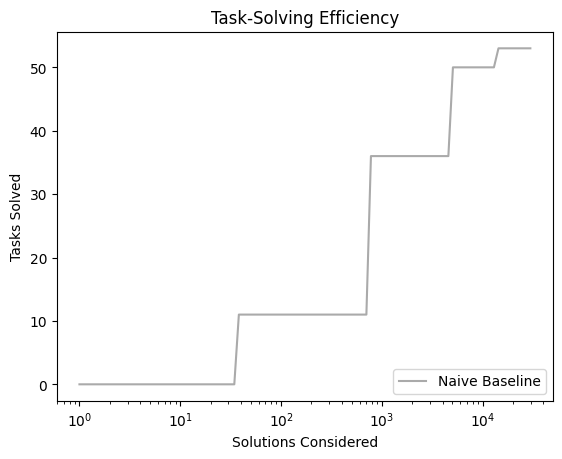

In [5]:
scores = plot_task_solving_efficiency(results)


### Complex Baseline: DeepCoder Approach

In [6]:
# DeepCoder enumeration with 1 NN

for p1 in ["Naive", "1", "2", "3", "All"]:

    label = f"DeepCoder-Style Enumeration - {p1}"

    metadata[label] = []

    for s in SEEDS:
        prediction_nn = DeepCoderNN(
            **DEEPCODER_HYPERPARAMS,
            grid_encoding_function=eval(f"encode_grid_{p1.lower()}"),
            seed=s,
        )
        prediction_nn.load_state_dict(torch.load(f"{MODELS_PATH}{p1}R_1000N_{s}S.pt", weights_only=True))
        prediction_nn.eval()

        metadata[label].append({
            "seed": s,
            "prediction_nns": [prediction_nn],
            "predictor_reduction": "Mean-Score",
            "demonstration_reduction": "Mean",
        })


In [7]:
results = try_all_tasks(metadata, results)



Now using: DeepCoder-Style Enumeration - Naive

Now solving 1cf80156...


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


... (2,707 outputs left out)

410it [00:00, 7054.98it/s]

Program found: `OneConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (411th attempt)
Correct: Found solution program 1 correctly solved all queries.



597it [00:00, 7263.13it/s]

Program found: `OneConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (598th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                     Naive Baseline: 0.359
	DeepCoder-Style Enumeration - Naive: 0.676
	    DeepCoder-Style Enumeration - 1: 0.672
	    DeepCoder-Style Enumeration - 2: 0.653
	    DeepCoder-Style Enumeration - 3: 0.671
	  DeepCoder-Style Enumeration - All: 0.664



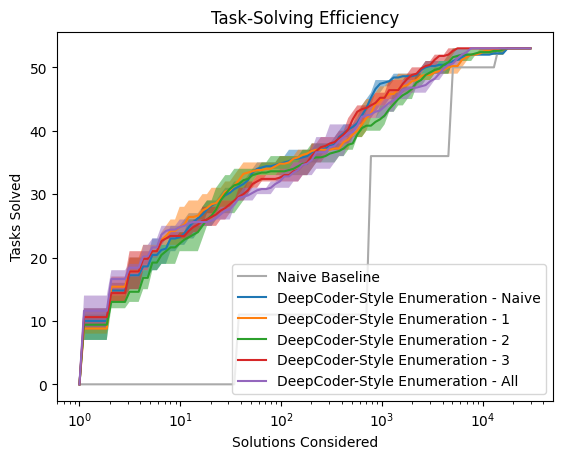

In [8]:
scores = plot_task_solving_efficiency(results)


In [9]:
# DeepCoder enumeration with NN ensemble

for p1 in ["Score-Mean", "Score-Min", "Score-Max", "Mean-Score", "Min-Score", "Max-Score"]:

    label = f"DeepCoder-Style Enumeration Ensemble - {p1}"

    metadata[label] = []

    for i, s in enumerate(SEEDS):
        metadata[label].append({
            "seed": s,
            "prediction_nns": [
                metadata["DeepCoder-Style Enumeration - 1"][i]["prediction_nns"][0],
                metadata["DeepCoder-Style Enumeration - 2"][i]["prediction_nns"][0],
                metadata["DeepCoder-Style Enumeration - 3"][i]["prediction_nns"][0],
            ],
            "predictor_reduction": p1,
            "demonstration_reduction": "Mean",
        })


In [10]:
results = try_all_tasks(metadata, results)



Now using: DeepCoder-Style Enumeration Ensemble - Score-Mean

Now solving 1cf80156...


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


... (3,201 outputs left out)

184it [00:00, 5282.64it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (185th attempt)
Correct: Found solution program 1 correctly solved all queries.


139it [00:00, 5075.90it/s]

Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (140th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                   Naive Baseline: 0.359
	              DeepCoder-Style Enumeration - Naive: 0.676
	                  DeepCoder-Style Enumeration - 1: 0.672
	                  DeepCoder-Style Enumeration - 2: 0.653
	                  DeepCoder-Style Enumeration - 3: 0.671
	                DeepCoder-Style Enumeration - All: 0.664
	DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.702
	 DeepCoder-Style Enumeration Ensemble - Score-Min: 0.678
	 DeepCoder-Style Enumeration Ensemble - Score-Max: 0.701
	DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.712
	 DeepCoder-Style Enumeration Ensemble - Min-Score: 0.667
	 DeepCoder-Style Enumeration Ensemble - Max-Score: 0.715



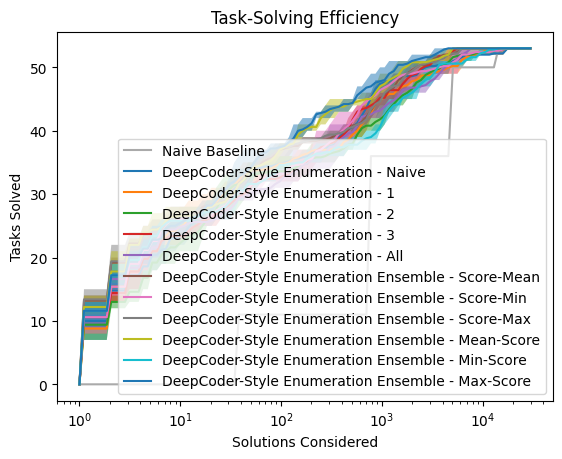

In [11]:
scores = plot_task_solving_efficiency(results)


### New Idea: VSA-Guided Synthesis

In [12]:
# Hybrid enumeration with 1 NN

for p1 in ["Naive", "1", "2", "3", "All"]:
    for p2 in ["Random", "Engineered SSP"]:

        label = f"Hybrid-VSA Enumeration - {p1} - {p2}"
    
        metadata[label] = []
    
        for i, s in enumerate(SEEDS):
            
            if (p2 == "Random"):
                embeddings = random_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    seed=s,
                )
            elif (p2 == "Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            else:
                assert False

            metadata[label].append({
                "seed": s,
                "prediction_nns": metadata[f"DeepCoder-Style Enumeration - {p1}"][i]["prediction_nns"],
                "predictor_reduction": "Mean-Project-Score",
                "demonstration_reduction": "Mean",
                "embeddings": embeddings,
                "projection_mode": "Matrix",
                "score_mode": "Softplus",
                "subtract_mode": "Conditioned",
                "beam_size": N_PRIMITIVES,
                "max_depth": 2,
            })


In [13]:
results = try_all_tasks(metadata, results)



Now using: Hybrid-VSA Enumeration - Naive - Random

Now solving 1cf80156...


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


... (5,309 outputs left out)

380it [00:00, 6709.39it/s]


Program found: `ColourHypothesis; Crop(ArgMax(x, ObjectGetPixelCount(x)())())()` correctly solved all demonstrations (381th attempt)
Correct: Found solution program 1 correctly solved all queries.


489it [00:00, 6621.52it/s]

Program found: `TwoConnectedHypothesis; Crop(ArgMax(x, ObjectGetPixelCount(x)())())()` correctly solved all demonstrations (490th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                   Naive Baseline: 0.359
	              DeepCoder-Style Enumeration - Naive: 0.676
	                  DeepCoder-Style Enumeration - 1: 0.672
	                  DeepCoder-Style Enumeration - 2: 0.653
	                  DeepCoder-Style Enumeration - 3: 0.671
	                DeepCoder-Style Enumeration - All: 0.664
	DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.702
	 DeepCoder-Style Enumeration Ensemble - Score-Min: 0.678
	 DeepCoder-Style Enumeration Ensemble - Score-Max: 0.701
	DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.712
	 DeepCoder-Style Enumeration Ensemble - Min-Score: 0.667
	 DeepCoder-Style Enumeration Ensemble - Max-Score: 0.715
	          Hybrid-VSA Enumeration - Naive - Random: 0.681
	  Hybrid-VSA Enumeration - Naive - Engineered SSP: 0.661
	              Hybrid-VSA Enumeration - 1 - Random: 0.684
	      Hybrid-VSA Enumeration - 1 - Engineered SSP: 0.664
	              Hybrid-VSA Enumera

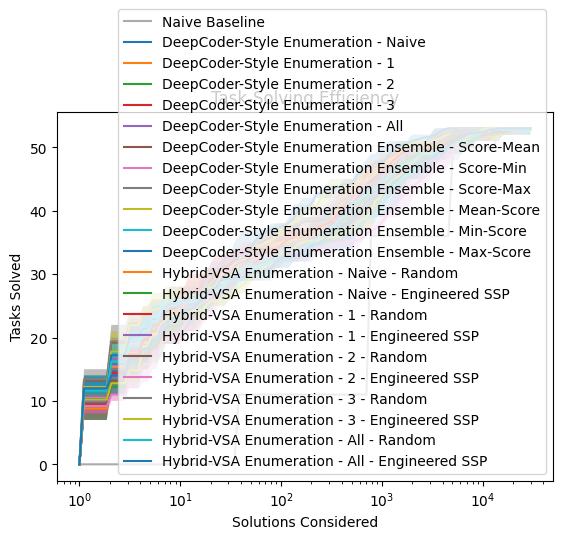

In [14]:
scores = plot_task_solving_efficiency(results)


In [15]:
# Hybrid enumeration with NN ensemble

for p1 in ["Project-Score-Mean", "Project-Score-Min", "Project-Score-Max", "Project-Mean-Score", "Mean-Project-Score", "Min-Project-Score", "Max-Project-Score"]:
    for p2 in ["Random", "Engineered SSP"]:

        label = f"Hybrid-VSA Enumeration Ensemble - {p1} - {p2}"

        metadata[label] = []
    
        for i, s in enumerate(SEEDS):
    
            if (p2 == "Random"):
                embeddings = random_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    seed=s,
                )
            elif (p2 == "Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            else:
                assert False
    
            metadata[label].append({
                "seed": s,
                "prediction_nns": [
                    metadata["DeepCoder-Style Enumeration - 1"][i]["prediction_nns"][0],
                    metadata["DeepCoder-Style Enumeration - 2"][i]["prediction_nns"][0],
                    metadata["DeepCoder-Style Enumeration - 3"][i]["prediction_nns"][0],
                ],
                "predictor_reduction": p1,
                "demonstration_reduction": "Mean",
                "embeddings": embeddings,
                "projection_mode": "Matrix",
                "score_mode": "Softplus",
                "subtract_mode": "Conditioned",
                "beam_size": N_PRIMITIVES,
                "max_depth": 2,
            })


In [16]:
results = try_all_tasks(metadata, results)



Now using: Hybrid-VSA Enumeration Ensemble - Project-Score-Mean - Random

Now solving 1cf80156...


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


... (7,431 outputs left out)

98it [00:00, 5072.77it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (99th attempt)
Correct: Found solution program 1 correctly solved all queries.


65it [00:00, 4186.83it/s]

Program found: `ColourHypothesis; Crop(ArgMax(x, ObjectGetPixelCount(x)())())()` correctly solved all demonstrations (66th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                                       Naive Baseline: 0.359
	                                  DeepCoder-Style Enumeration - Naive: 0.676
	                                      DeepCoder-Style Enumeration - 1: 0.672
	                                      DeepCoder-Style Enumeration - 2: 0.653
	                                      DeepCoder-Style Enumeration - 3: 0.671
	                                    DeepCoder-Style Enumeration - All: 0.664
	                    DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.702
	                     DeepCoder-Style Enumeration Ensemble - Score-Min: 0.678
	                     DeepCoder-Style Enumeration Ensemble - Score-Max: 0.701
	                    DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.712
	                     DeepCoder-Style Enumeration Ensemble - Min-Score: 0.667
	                     DeepCoder-Style Enumeration Ensemble - Max-Score: 0.715
	                        

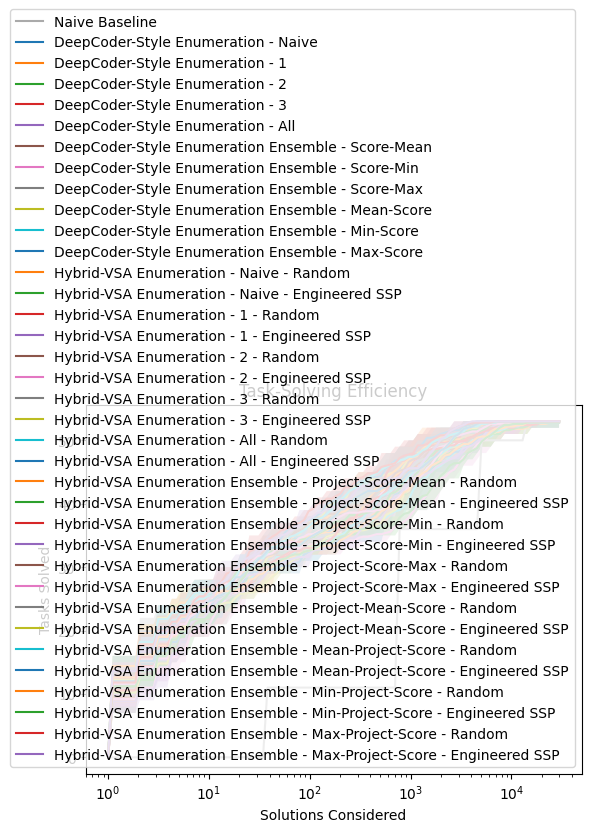

In [17]:
scores = plot_task_solving_efficiency(results)


In [18]:
# GOAT-DeepCoder evolution with 1 NN

for p1 in ["Naive", "1", "2", "3", "All"]:

    label = f"DeepCoder-Style GOAT Evolution - {p1}"

    metadata[label] = []

    for i, s in enumerate(SEEDS):
        embeddings = random_embeddings(
            embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
            seed=s,
        )

        metadata[label].append({
            "seed": s,
            "prediction_nns": metadata[f"DeepCoder-Style Enumeration - {p1}"][i]["prediction_nns"],
            "predictor_reduction": "Mean-Score",
            "demonstration_reduction": "Mean",
            "embeddings": embeddings,
            "projection_mode": "Matrix",
            "score_mode": "Softplus",
            "subtract_mode": "Conditioned",
            "beam_size": N_PRIMITIVES,
            "max_depth": 2,
            "update_weight": 0,
            "encoding_reduction": "Mean",
            "intermediate_reduction": "Rectify-Mean",
            "formula": "Default",
            "fix_deep": True,
            "ranker": "DeepCoder",
            "encode_fcns": [eval(f"encode_grid_{p1.lower()}")],
        })


In [19]:
results = try_all_tasks(metadata, results)



Now using: DeepCoder-Style GOAT Evolution - Naive

Now solving 1cf80156...
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 28bf18c6...
Program found: "GridHypothesis; HStack(Crop(x)(), Crop(x)())()" correctly solved all demonstrations (9th attempt)


37it [00:00, 9612.22it/s]


Program found: `GridHypothesis; VStack(x, VFlip(x)())()` correctly solved all demonstrations (38th attempt)
Correct: Found solution program 1 correctly solved all queries.


44it [00:00, 10511.44it/s]


Program found: `GridHypothesis; VStack(x, VFlip(x)())()` correctly solved all demonstrations (45th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 9172f3a0...
Program found: "GridHypothesis; Scale(x, NumberConstant(Number(3))())()" correctly solved all demonstrations (2th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Scale(x, NumberConstant(Number(3))())()" correctly solved all demonstrations (2th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Scale(x, NumberConstant(Number(3))())()" correctly solved all demonstrations (2th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Scale(x, NumberConstant(Number(3))())()" correctly solved all demonstrations (2th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Scale(x, NumberConstant

28it [00:00, 7734.49it/s]


... (741 outputs left out)

330it [00:00, 6137.27it/s]


Program found: `OneConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (331th attempt)
Correct: Found solution program 1 correctly solved all queries.


526it [00:00, 7803.91it/s]

Program found: `OneConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (527th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                                       Naive Baseline: 0.359
	                                  DeepCoder-Style Enumeration - Naive: 0.676
	                                      DeepCoder-Style Enumeration - 1: 0.672
	                                      DeepCoder-Style Enumeration - 2: 0.653
	                                      DeepCoder-Style Enumeration - 3: 0.671
	                                    DeepCoder-Style Enumeration - All: 0.664
	                    DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.702
	                     DeepCoder-Style Enumeration Ensemble - Score-Min: 0.678
	                     DeepCoder-Style Enumeration Ensemble - Score-Max: 0.701
	                    DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.712
	                     DeepCoder-Style Enumeration Ensemble - Min-Score: 0.667
	                     DeepCoder-Style Enumeration Ensemble - Max-Score: 0.715
	                        

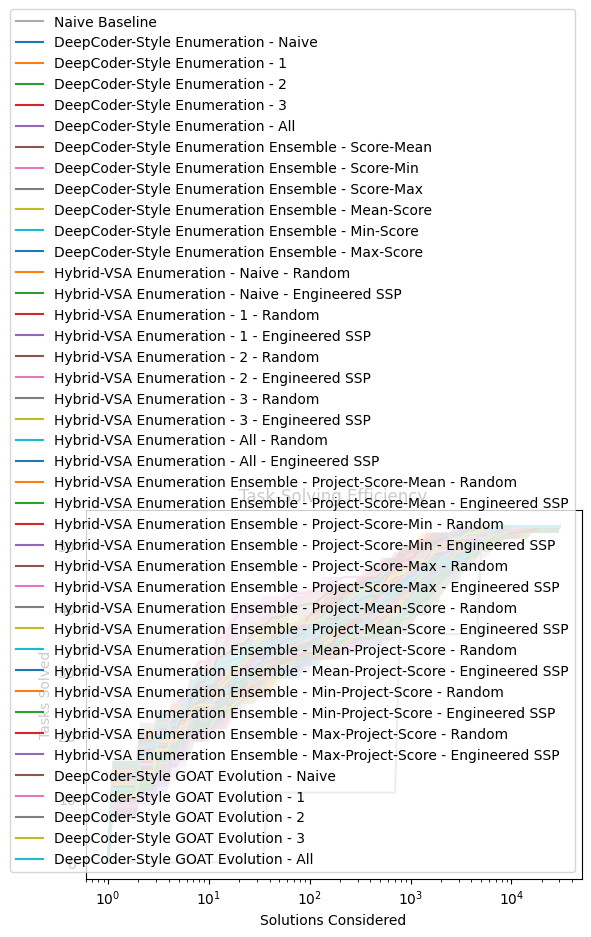

In [20]:
scores = plot_task_solving_efficiency(results)


In [21]:
# GOAT-Hybrid evolution with 1 NN

for p1 in ["Naive", "1", "2", "3", "All"]:
    for p2 in ["Random", "Engineered SSP"]:

        label = f"Hybrid GOAT Evolution - {p1} - {p2}"
    
        metadata[label] = []
    
        for i, s in enumerate(SEEDS):

            if (p2 == "Random"):
                embeddings = random_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    seed=s,
                )
            elif (p2 == "Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            else:
                assert False
    
            metadata[label].append({
                "seed": s,
                "prediction_nns": metadata[f"DeepCoder-Style Enumeration - {p1}"][i]["prediction_nns"],
                "predictor_reduction": "Mean-Project-Score",
                "demonstration_reduction": "Mean",
                "embeddings": embeddings,
                "projection_mode": "Matrix",
                "score_mode": "Softplus",
                "subtract_mode": "Conditioned",
                "beam_size": N_PRIMITIVES,
                "max_depth": 2,
                "update_weight": 0,
                "encoding_reduction": "Mean",
                "intermediate_reduction": "Rectify-Mean",
                "formula": "Default",
                "fix_deep": True,
                "ranker": "Hybrid",
                "encode_fcns": [eval(f"encode_grid_{p1.lower()}")],
            })


In [22]:
results = try_all_tasks(metadata, results)



Now using: Hybrid GOAT Evolution - Naive - Random

Now solving 1cf80156...
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 28bf18c6...
Program found: "GridHypothesis; HStack(Crop(x)(), Crop(x)())()" correctly solved all demonstrations (5th attempt)


27it [00:00, 9437.97it/s]


Program found: `GridHypothesis; VStack(x, VFlip(x)())()` correctly solved all demonstrations (28th attempt)
Correct: Found solution program 1 correctly solved all queries.


38it [00:00, 10098.43it/s]


Program found: `GridHypothesis; VStack(x, VFlip(x)())()` correctly solved all demonstrations (39th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 9172f3a0...
Program found: "GridHypothesis; Scale(x, NumberConstant(Number(3))())()" correctly solved all demonstrations (2th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Scale(x, NumberConstant(Number(3))())()" correctly solved all demonstrations (2th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Scale(x, NumberConstant(Number(3))())()" correctly solved all demonstrations (2th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Scale(x, NumberConstant(Number(3))())()" correctly solved all demonstrations (2th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Scale(x, NumberConstant

7it [00:00, 7667.83it/s]


... (1,362 outputs left out)

241it [00:00, 6516.38it/s]


Program found: `ColourHypothesis; Crop(ArgMax(x, ObjectGetPixelCount(x)())())()` correctly solved all demonstrations (242th attempt)
Correct: Found solution program 1 correctly solved all queries.


331it [00:00, 6838.58it/s]

Program found: `TwoConnectedHypothesis; Crop(ArgMax(x, ObjectGetPixelCount(x)())())()` correctly solved all demonstrations (332th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                                       Naive Baseline: 0.359
	                                  DeepCoder-Style Enumeration - Naive: 0.676
	                                      DeepCoder-Style Enumeration - 1: 0.672
	                                      DeepCoder-Style Enumeration - 2: 0.653
	                                      DeepCoder-Style Enumeration - 3: 0.671
	                                    DeepCoder-Style Enumeration - All: 0.664
	                    DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.702
	                     DeepCoder-Style Enumeration Ensemble - Score-Min: 0.678
	                     DeepCoder-Style Enumeration Ensemble - Score-Max: 0.701
	                    DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.712
	                     DeepCoder-Style Enumeration Ensemble - Min-Score: 0.667
	                     DeepCoder-Style Enumeration Ensemble - Max-Score: 0.715
	                        

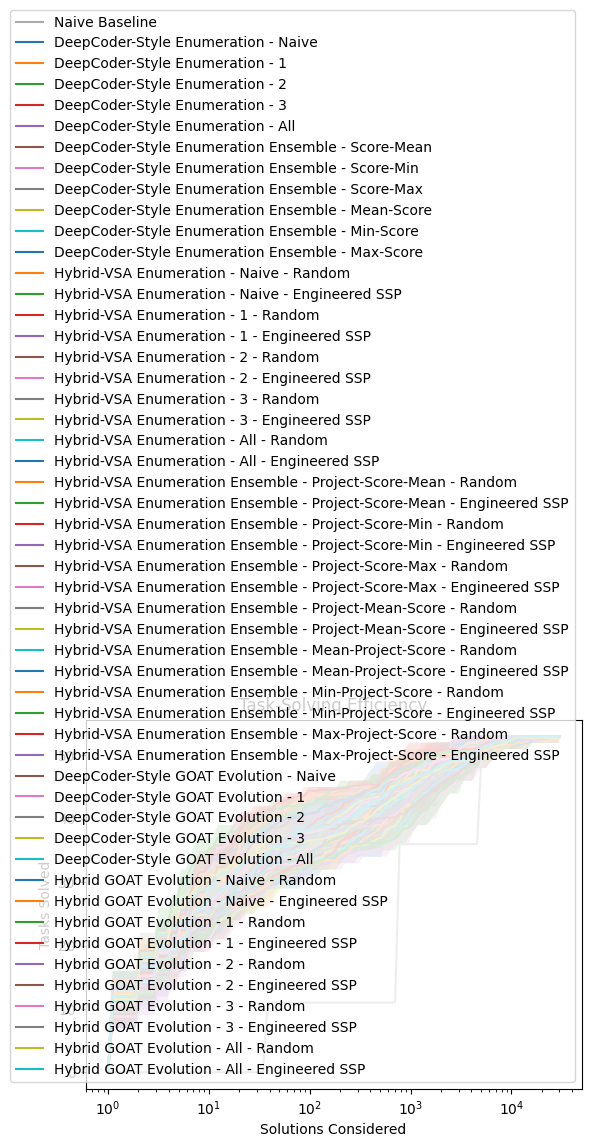

In [23]:
scores = plot_task_solving_efficiency(results)


In [24]:
# GOAT-DeepCoder evolution with NN ensemble

for p1 in ["Score-Mean", "Score-Min", "Score-Max", "Mean-Score", "Min-Score", "Max-Score"]:

    label = f"DeepCoder-Style GOAT Evolution Ensemble - {p1}"

    metadata[label] = []

    for i, s in enumerate(SEEDS):
        embeddings = random_embeddings(
            embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
            seed=s,
        )

        metadata[label].append({
            "seed": s,
            "prediction_nns": [
                metadata["DeepCoder-Style Enumeration - 1"][i]["prediction_nns"][0],
                metadata["DeepCoder-Style Enumeration - 2"][i]["prediction_nns"][0],
                metadata["DeepCoder-Style Enumeration - 3"][i]["prediction_nns"][0],
            ],
            "predictor_reduction": p1,
            "demonstration_reduction": "Mean",
            "embeddings": embeddings,
            "projection_mode": "Matrix",
            "score_mode": "Softplus",
            "subtract_mode": "Conditioned",
            "beam_size": N_PRIMITIVES,
            "max_depth": 2,
            "update_weight": 0,
            "encoding_reduction": "Max",
            "intermediate_reduction": "Rectify-Mean",
            "formula": "Default",
            "fix_deep": True,
            "ranker": "DeepCoder",
            "encode_fcns": [eval("encode_grid_1"), eval("encode_grid_2"), eval("encode_grid_3")],
        })


In [25]:
results = try_all_tasks(metadata, results)



Now using: DeepCoder-Style GOAT Evolution Ensemble - Score-Mean

Now solving 1cf80156...
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 28bf18c6...
Program found: "GridHypothesis; HStack(Crop(x)(), Crop(x)())()" correctly solved all demonstrations 

35it [00:00, 3526.15it/s]


Program found: `GridHypothesis; VStack(x, VFlip(x)())()` correctly solved all demonstrations (36th attempt)
Correct: Found solution program 1 correctly solved all queries.


87it [00:00, 4349.74it/s]


Program found: `GridHypothesis; VStack(x, VFlip(x)())()` correctly solved all demonstrations (88th attempt)
Correct: Found solution program 1 correctly solved all queries.


48it [00:00, 5004.14it/s]


... (679 outputs left out)

85it [00:00, 4017.03it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (86th attempt)
Correct: Found solution program 1 correctly solved all queries.


54it [00:00, 3694.34it/s]

Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (55th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                                       Naive Baseline: 0.359
	                                  DeepCoder-Style Enumeration - Naive: 0.676
	                                      DeepCoder-Style Enumeration - 1: 0.672
	                                      DeepCoder-Style Enumeration - 2: 0.653
	                                      DeepCoder-Style Enumeration - 3: 0.671
	                                    DeepCoder-Style Enumeration - All: 0.664
	                    DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.702
	                     DeepCoder-Style Enumeration Ensemble - Score-Min: 0.678
	                     DeepCoder-Style Enumeration Ensemble - Score-Max: 0.701
	                    DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.712
	                     DeepCoder-Style Enumeration Ensemble - Min-Score: 0.667
	                     DeepCoder-Style Enumeration Ensemble - Max-Score: 0.715
	                        

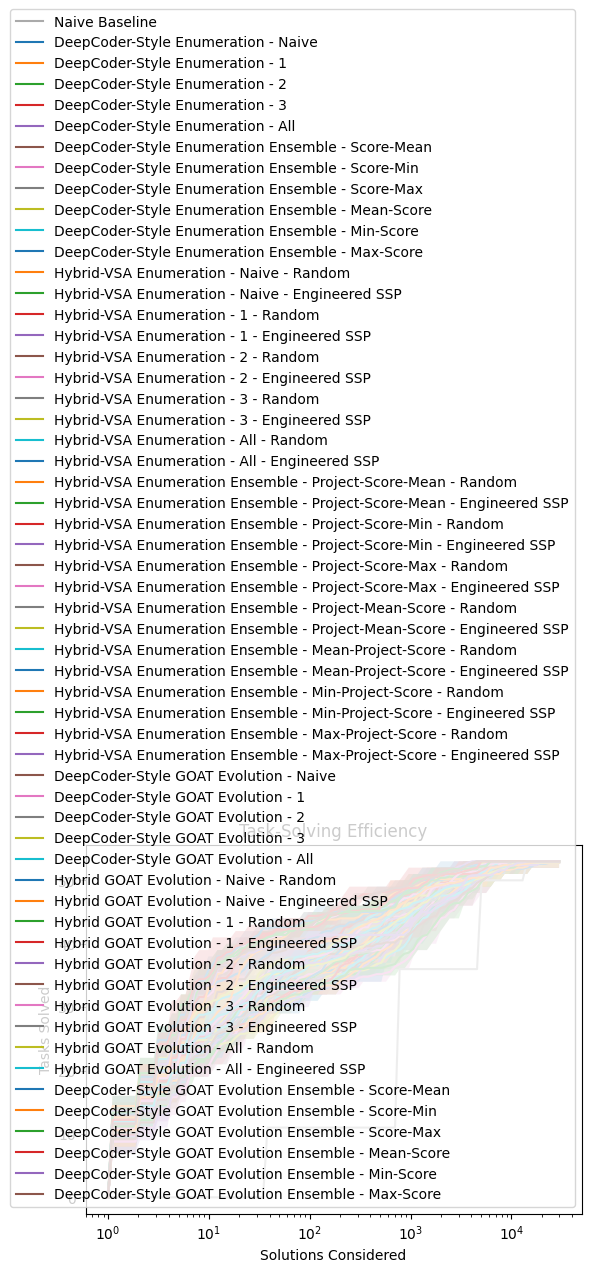

In [26]:
scores = plot_task_solving_efficiency(results)


In [27]:
# GOAT-Hybrid evolution with NN ensemble

for p1 in ["Project-Score-Mean", "Project-Score-Max", "Project-Mean-Score", "Mean-Project-Score"]:
    for p2 in ["Random", "Typetagged Learned SSP", "Engineered SSP"]:

        label = f"Hybrid GOAT Evolution Ensemble - {p1} - {p2}"

        metadata[label] = []

        for i, s in enumerate(SEEDS):

            if (p2 == "Random"):
                embeddings = random_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    seed=s,
                )
            elif (p2 == "Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            else:
                assert False

            metadata[label].append({
                "seed": s,
                "prediction_nns": [
                    metadata["DeepCoder-Style Enumeration - 1"][i]["prediction_nns"][0],
                    metadata["DeepCoder-Style Enumeration - 2"][i]["prediction_nns"][0],
                    metadata["DeepCoder-Style Enumeration - 3"][i]["prediction_nns"][0],
                ],
                "predictor_reduction": p1,
                "demonstration_reduction": "Mean",
                "embeddings": embeddings,
                "projection_mode": "Matrix",
                "score_mode": "Softplus",
                "subtract_mode": "Conditioned",
                "beam_size": N_PRIMITIVES,
                "max_depth": 2,
                "update_weight": 0,
                "encoding_reduction": "Max",
                "intermediate_reduction": "Rectify-Mean",
                "formula": "Default",
                "fix_deep": True,
                "ranker": "Hybrid",
                "encode_fcns": [eval("encode_grid_1"), eval("encode_grid_2"), eval("encode_grid_3")],
            })


In [28]:
results = try_all_tasks(metadata, results)



Now using: Hybrid GOAT Evolution Ensemble - Project-Score-Mean - Random

Now solving 1cf80156...
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 28bf18c6...
Program found: "GridHypothesis; HStack(Crop(x)(), Crop(x)())()" correctly solved all demonst

30it [00:00, 4606.09it/s]


Program found: `GridHypothesis; VStack(x, VFlip(x)())()` correctly solved all demonstrations (31th attempt)
Correct: Found solution program 1 correctly solved all queries.


73it [00:00, 4307.78it/s]


Program found: `GridHypothesis; VStack(x, VFlip(x)())()` correctly solved all demonstrations (74th attempt)
Correct: Found solution program 1 correctly solved all queries.


36it [00:00, 4175.51it/s]


... (831 outputs left out)

1770it [00:00, 3200.16it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (1771th attempt)
Correct: Found solution program 1 correctly solved all queries.


1711it [00:00, 3363.22it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (1712th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving be94b721...
Program found: "OneConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()" correctly solved all demonstrations (74th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()" correctly solved all demonstrations (81th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "OneConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()" correctly solved all demonstrations (80th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()" correctly solved all demonstrations (80th attempt)
Correct: Found solution program 1 corre

Scores (Average Area Under the Curve):
	                                                              Naive Baseline: 0.359
	                                         DeepCoder-Style Enumeration - Naive: 0.676
	                                             DeepCoder-Style Enumeration - 1: 0.672
	                                             DeepCoder-Style Enumeration - 2: 0.653
	                                             DeepCoder-Style Enumeration - 3: 0.671
	                                           DeepCoder-Style Enumeration - All: 0.664
	                           DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.702
	                            DeepCoder-Style Enumeration Ensemble - Score-Min: 0.678
	                            DeepCoder-Style Enumeration Ensemble - Score-Max: 0.701
	                           DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.712
	                            DeepCoder-Style Enumeration Ensemble - Min-Score: 0.667
	                         

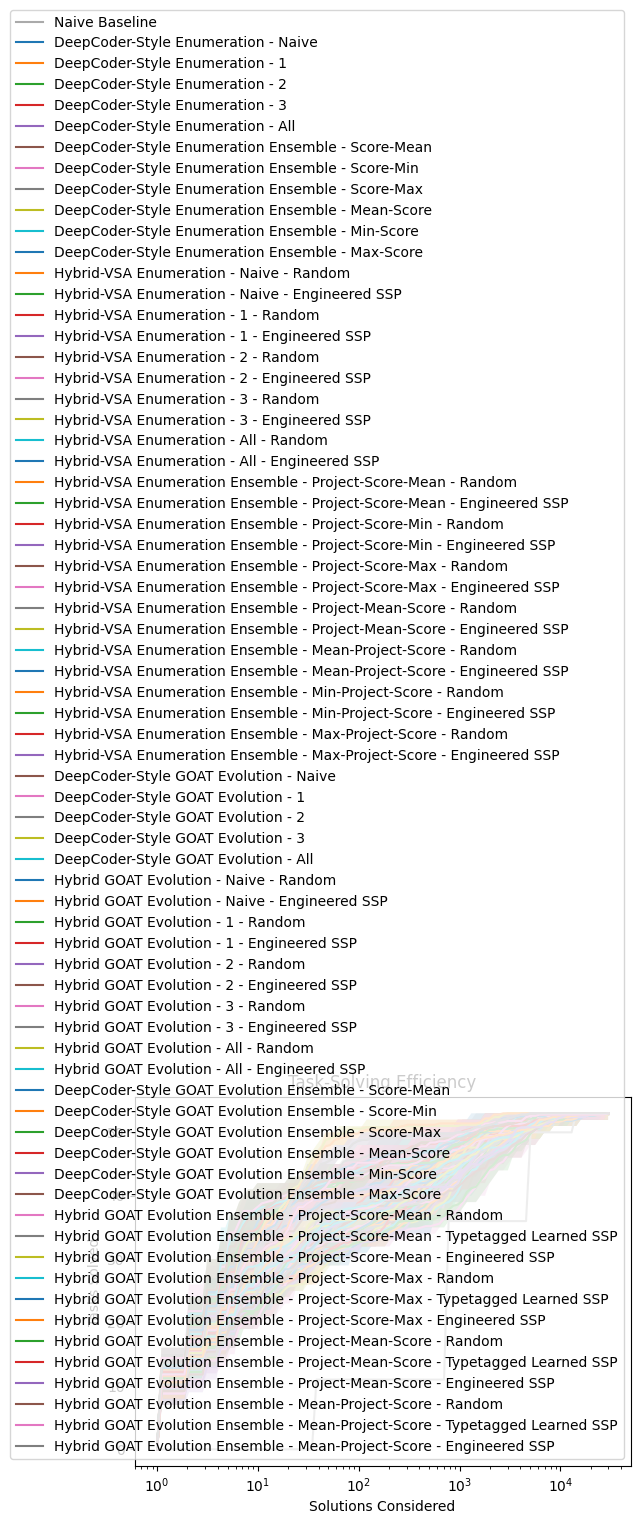

In [29]:
scores = plot_task_solving_efficiency(results)


In [ ]:
np.savez("../results/1K_Data.npz", **results)
